# Feature analysis

Scores are fit on the training side of one 80/20 split (`VAL_RATIO`, `RANDOM_STATE`), after the same column clean and a z-score fit on that side only. The holdout is not used.

Blue is in both top-150 lists (correlation and mutual information). Green is mutual information only. Orange is correlation only. Grey is neither.

Plots cover agreement, redundancy, age exemplars, Spearman, disagreement redundancy with the blue core, fold pick rates, and where Monte Carlo, cluster-then-pick, correlation mRMR, and RReliefF land on the same scatter.


In [4]:
import base64
import os
import sys
from io import BytesIO
from pathlib import Path

import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "lib")]

from GLOBAL import CV_FOLDS, FS_CORR_MAX, FS_K, RANDOM_STATE, VAL_RATIO
from clean import clean
from load import load
from select_features.drop_high_corr import drop_high_corr

X, y, _ = load()
X, _ = clean(X)
y = np.ravel(y)
X_tr_raw, _, y_tr, _ = train_test_split(X, y, test_size=VAL_RATIO, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_tr_raw)
X_tr = pd.DataFrame(scaler.transform(X_tr_raw), index=X_tr_raw.index, columns=X_tr_raw.columns)
y_tr = pd.Series(y_tr, index=X_tr.index)
print(f"score rows {len(X_tr)}  columns {X_tr.shape[1]}")

def show_fig(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=140)
    raw = buf.getvalue()
    plt.close(fig)
    display(HTML(
        '<img src="data:image/png;base64,'
        + base64.b64encode(raw).decode("ascii")
        + '" style="max-width:100%"/>'
    ))


Dropping 4 dead columns: ['x104', 'x129', 'x489', 'x530']
Keeping insane-absmax columns
score rows 969  columns 828


top 150 overlap 87  corr only 63  mi only 63



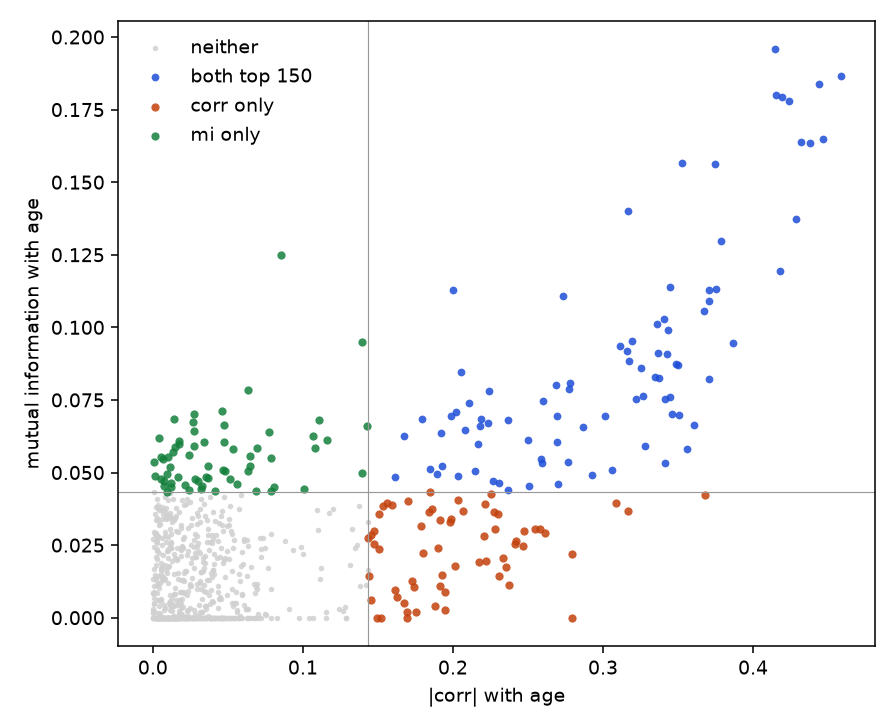

In [5]:
abs_r = X_tr.corrwith(y_tr).abs().fillna(0)
mi = pd.Series(
    mutual_info_regression(X_tr, y_tr.to_numpy(), random_state=RANDOM_STATE, n_jobs=-1),
    index=X_tr.columns,
)
corr_top = set(abs_r.nlargest(FS_K).index)
mi_top = set(mi.nlargest(FS_K).index)
both = corr_top & mi_top
corr_only = corr_top - mi_top
mi_only = mi_top - corr_top
neither = set(X_tr.columns) - corr_top - mi_top
print(f"top {FS_K} overlap {len(both)}  corr only {len(corr_only)}  mi only {len(mi_only)}")

fig, ax = plt.subplots(figsize=(6.4, 5.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
groups = (
    (neither, "#d0d0d0", 8, "neither"),
    (both, "#1d4ed8", 16, "both top 150"),
    (corr_only, "#c2410c", 18, "corr only"),
    (mi_only, "#15803d", 18, "mi only"),
)
for idx, color, size, label in groups:
    cols = list(idx)
    ax.scatter(abs_r.loc[cols], mi.loc[cols], s=size, c=color, alpha=0.85, label=label, linewidths=0)
ax.axvline(abs_r.nlargest(FS_K).iloc[-1], color="#999", lw=0.6)
ax.axhline(mi.nlargest(FS_K).iloc[-1], color="#999", lw=0.6)
ax.set_xlabel("|corr| with age")
ax.set_ylabel("mutual information with age")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ROOT / "experiments/008/corr_vs_mi.png", dpi=140)
show_fig(fig)


High-corr drop |r|>=0.95: ['x278', 'x317', 'x579', 'x774']
kept 150  pairs |r|>=0.5: 2911  |r|>=0.7: 670



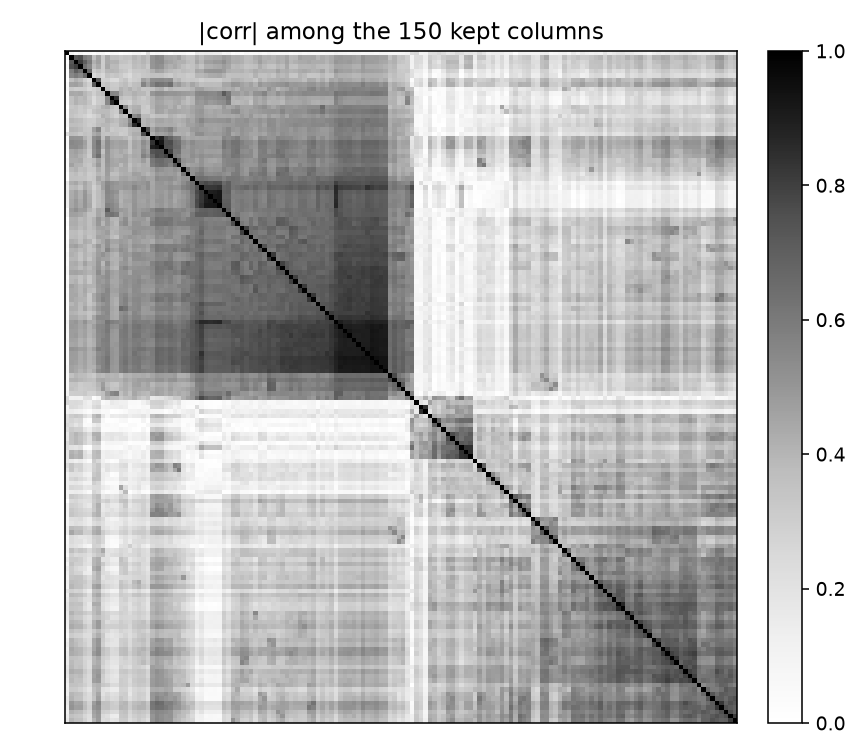

In [6]:
kept = drop_high_corr(X_tr, y_tr, FS_CORR_MAX)
chosen = abs_r.loc[kept].nlargest(min(FS_K, len(kept))).index.tolist()
block = X_tr[chosen].corr().abs()
dist = squareform(np.clip(1 - block.to_numpy(), 0, None), checks=False)
order = leaves_list(linkage(dist, method="average"))
block = block.iloc[order, order]
pairs = block.to_numpy()
upper = pairs[np.triu_indices_from(pairs, k=1)]
print(f"kept {len(chosen)}  pairs |r|>=0.5: {(upper >= 0.5).sum()}  |r|>=0.7: {(upper >= 0.7).sum()}")

fig, ax = plt.subplots(figsize=(6.2, 5.4))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
image = ax.imshow(block.to_numpy(), cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"|corr| among the {len(chosen)} kept columns")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(ROOT / "experiments/008/kept_corr.png", dpi=140)
show_fig(fig)


both x458: |r|=0.458  mi=0.186
mi only hi x742: |r|=0.085  mi=0.125
mi only mid x742: |r|=0.085  mi=0.125
corr only x531: |r|=0.368  mi=0.042



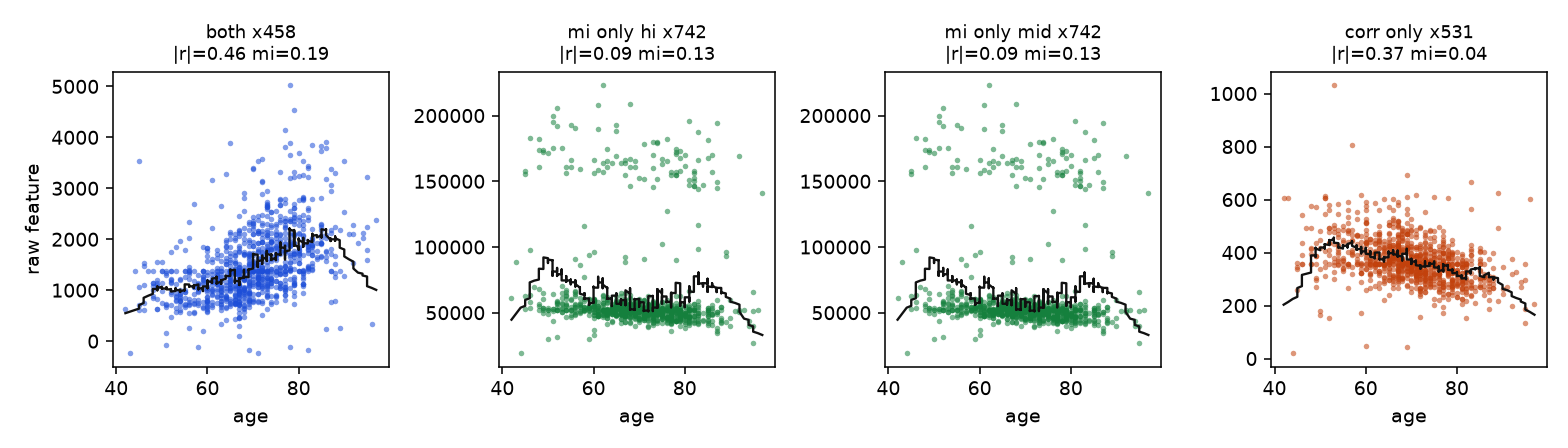

In [ ]:
blue_col = abs_r.loc[list(both)].idxmax()
green_hi = mi.loc[list(mi_only)].idxmax()
green_mid = ((abs_r.loc[list(mi_only)] - 0.08).abs() + (mi.loc[list(mi_only)] - 0.12).abs()).idxmin()
orange_hi = abs_r.loc[list(corr_only)].idxmax()
exemplars = (
    (blue_col, "#1d4ed8", f"both {blue_col}"),
    (green_hi, "#15803d", f"mi only hi {green_hi}"),
    (green_mid, "#15803d", f"mi only mid {green_mid}"),
    (orange_hi, "#c2410c", f"corr only {orange_hi}"),
)
for col, _, label in exemplars:
    print(f"{label}: |r|={abs_r[col]:.3f}  mi={mi[col]:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(11.2, 3.2), sharey=False)
fig.patch.set_facecolor("white")
for ax, (col, color, label) in zip(axes, exemplars):
    ax.set_facecolor("white")
    xv = y_tr.to_numpy()
    yv = X_tr_raw.loc[X_tr.index, col].to_numpy()
    ax.scatter(xv, yv, s=8, c=color, alpha=0.55, linewidths=0)
    order = np.argsort(xv)
    xs, ys = xv[order], yv[order]
    if len(xs) >= 30:
        win = max(15, len(xs) // 25)
        kernel = np.ones(win) / win
        ax.plot(xs, np.convolve(ys, kernel, mode="same"), color="#111", lw=1.2)
    ax.set_title(f"{label}\n|r|={abs_r[col]:.2f} mi={mi[col]:.2f}", fontsize=9)
    ax.set_xlabel("age")
axes[0].set_ylabel("raw feature")
fig.tight_layout()
fig.savefig(ROOT / "experiments/008/age_exemplars.png", dpi=140)
show_fig(fig)

spearman vs pearson: median |rho|-|r|=0.007  green mean |rho|=0.054  green mean |r|=0.045



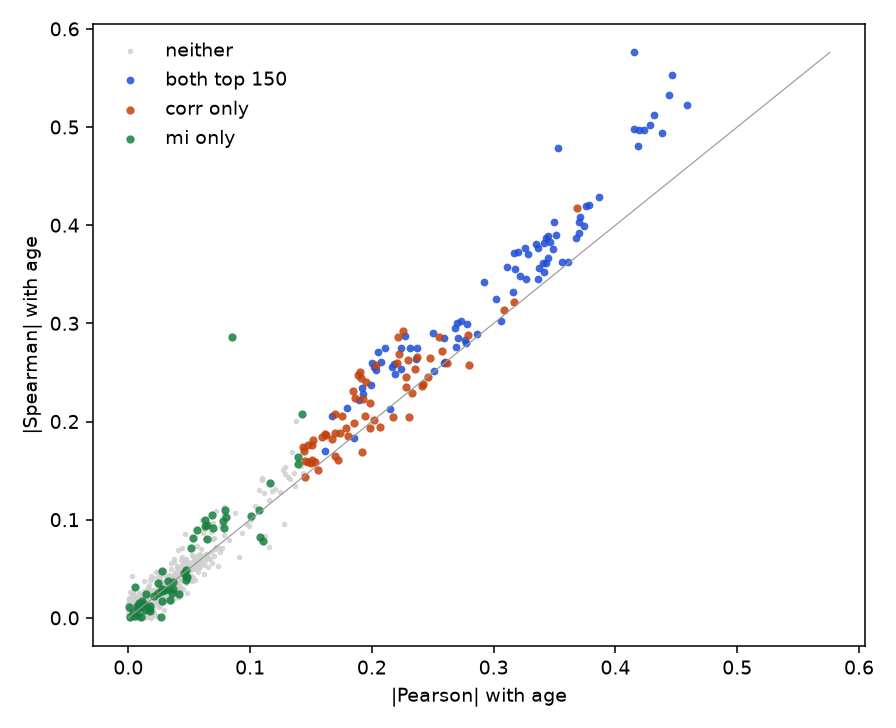

In [8]:
abs_rho = X_tr.corrwith(y_tr, method="spearman").abs().fillna(0)
print(
    f"spearman vs pearson: median |rho|-|r|={(abs_rho - abs_r).abs().median():.3f}  "
    f"green mean |rho|={abs_rho.loc[list(mi_only)].mean():.3f}  "
    f"green mean |r|={abs_r.loc[list(mi_only)].mean():.3f}"
)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
for idx, color, size, label in groups:
    cols = list(idx)
    ax.scatter(abs_r.loc[cols], abs_rho.loc[cols], s=size, c=color, alpha=0.85, label=label, linewidths=0)
lo, hi = 0.0, float(max(abs_r.max(), abs_rho.max()))
ax.plot([lo, hi], [lo, hi], color="#999", lw=0.6)
ax.set_xlabel("|Pearson| with age")
ax.set_ylabel("|Spearman| with age")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ROOT / "experiments/008/pearson_vs_spearman.png", dpi=140)
show_fig(fig)

max |r| with blue: green med=0.086  orange med=0.725  green |r|>=0.7=16



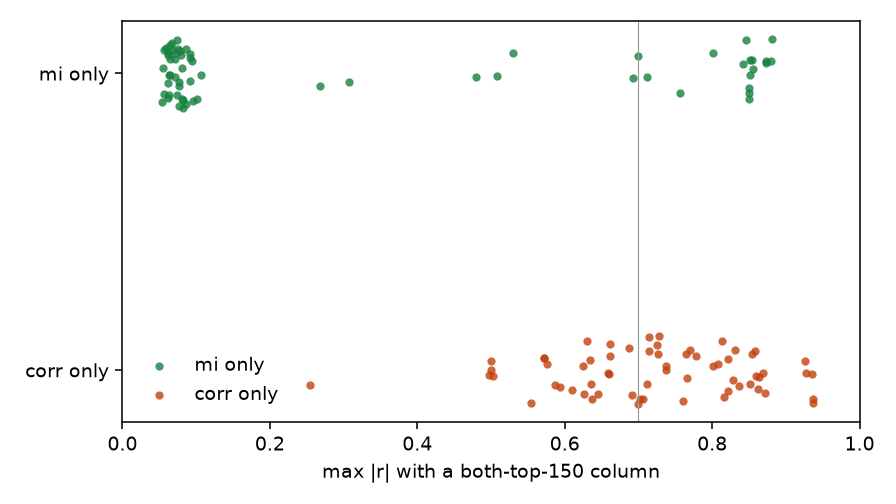

In [9]:
blue_cols = list(both)
dis = list(mi_only) + list(corr_only)
max_r_blue = X_tr[dis + blue_cols].corr().abs().loc[dis, blue_cols].max(axis=1)
print(
    f"max |r| with blue: green med={max_r_blue.loc[list(mi_only)].median():.3f}  "
    f"orange med={max_r_blue.loc[list(corr_only)].median():.3f}  "
    f"green |r|>=0.7={(max_r_blue.loc[list(mi_only)] >= 0.7).sum()}"
)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
rng = np.random.default_rng(RANDOM_STATE)
for name, cols, color, y0 in (
    ("mi only", list(mi_only), "#15803d", 1.0),
    ("corr only", list(corr_only), "#c2410c", 0.0),
):
    vals = max_r_blue.loc[cols].to_numpy()
    jitter = rng.uniform(-0.12, 0.12, size=len(vals))
    ax.scatter(vals, np.full(len(vals), y0) + jitter, s=18, c=color, alpha=0.8, label=name, linewidths=0)
ax.axvline(0.7, color="#999", lw=0.6)
ax.set_yticks([0.0, 1.0], ["corr only", "mi only"])
ax.set_xlabel("max |r| with a both-top-150 column")
ax.set_xlim(0, 1)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ROOT / "experiments/008/disagreement_redundancy.png", dpi=140)
show_fig(fig)

fold pick rate <0.5: corr=64  mi=103  of 213 watched



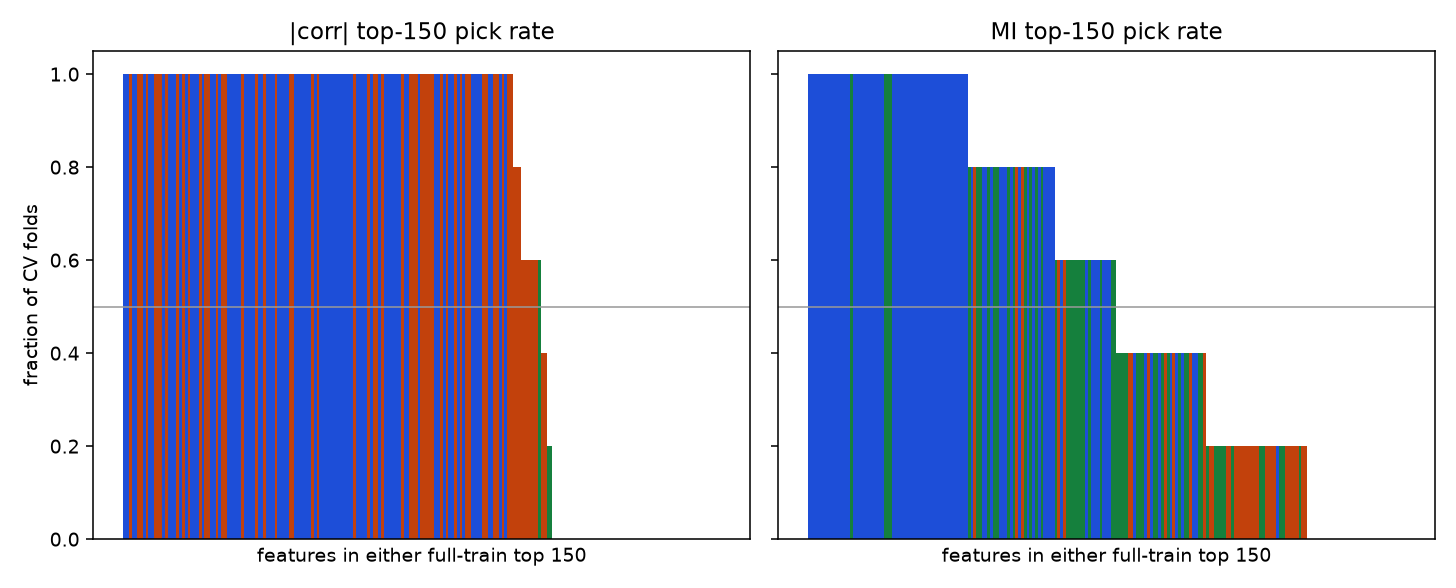

In [ ]:
from sklearn.model_selection import KFold

watch = sorted(corr_top | mi_top)
corr_hits = pd.Series(0, index=watch, dtype=float)
mi_hits = pd.Series(0, index=watch, dtype=float)
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for train_idx, _ in kf.split(X_tr):
    X_fold = X_tr.iloc[train_idx]
    y_fold = y_tr.iloc[train_idx]
    fold_r = X_fold.corrwith(y_fold).abs().fillna(0)
    fold_mi = pd.Series(
        mutual_info_regression(X_fold, y_fold.to_numpy(), random_state=RANDOM_STATE, n_jobs=-1),
        index=X_fold.columns,
    )
    corr_hits.loc[fold_r.nlargest(FS_K).index.intersection(watch)] += 1
    mi_hits.loc[fold_mi.nlargest(FS_K).index.intersection(watch)] += 1
corr_hits /= CV_FOLDS
mi_hits /= CV_FOLDS
color_of = {c: "#1d4ed8" for c in both}
color_of.update({c: "#15803d" for c in mi_only})
color_of.update({c: "#c2410c" for c in corr_only})
print(
    f"fold pick rate <0.5: corr={(corr_hits < 0.5).sum()}  mi={(mi_hits < 0.5).sum()}  "
    f"of {len(watch)} watched"
)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2), sharey=True)
fig.patch.set_facecolor("white")
for ax, rates, title in (
    (axes[0], corr_hits, "|corr| top-150 pick rate"),
    (axes[1], mi_hits, "MI top-150 pick rate"),
):
    ax.set_facecolor("white")
    order = rates.sort_values(ascending=False).index
    ax.bar(np.arange(len(order)), rates.loc[order], color=[color_of[c] for c in order], width=1.0)
    ax.axhline(0.5, color="#999", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("features in either full-train top 150")
    ax.set_xticks([])
axes[0].set_ylabel("fraction of CV folds")
fig.tight_layout()
fig.savefig(ROOT / "experiments/008/selection_stability.png", dpi=140)
show_fig(fig)

corr select: top 150/824  |r|[min,med,max]=0.1434,0.2393,0.4584
Round 0: 824→813  best 0.246  mean 0.093  worst -0.046
Round 1: 813→813  best 0.295  mean 0.049  worst -0.171
Round 2: 813→811  best 0.299  mean 0.073  worst -0.099
Round 3: 811→811  best 0.287  mean 0.074  worst -0.057
Round 4: 811→811  best 0.213  mean 0.069  worst -0.099
Round 5: 811→807  best 0.284  mean 0.086  worst -0.098
Round 6: 807→806  best 0.224  mean 0.061  worst -0.122
Round 7: 806→802  best 0.244  mean 0.082  worst -0.100
Round 8: 802→777  best 0.198  mean 0.077  worst -0.067
Round 9: 777→777  best 0.222  mean 0.073  worst -0.139
feature  r0    r1    r2    r3    r4    r5    r6    r7    r8    r9   r10  alive
    x70   0  45.6  86.2 153.9 205.5 268.0 350.4 385.9 427.1 494.4 547.3   True
   x638   0  -1.2  -1.2  -1.2  -1.2  -1.2  -1.2  -1.2  -1.2  -1.2  -1.2  False
    x72   0  53.6  99.9 186.3 213.1 229.0 297.0 345.0 371.3 405.9 472.2   True
   x540   0  32.6  57.1 137.9 213.2 247.5 295.8 371.2 452.4 521.4 539.


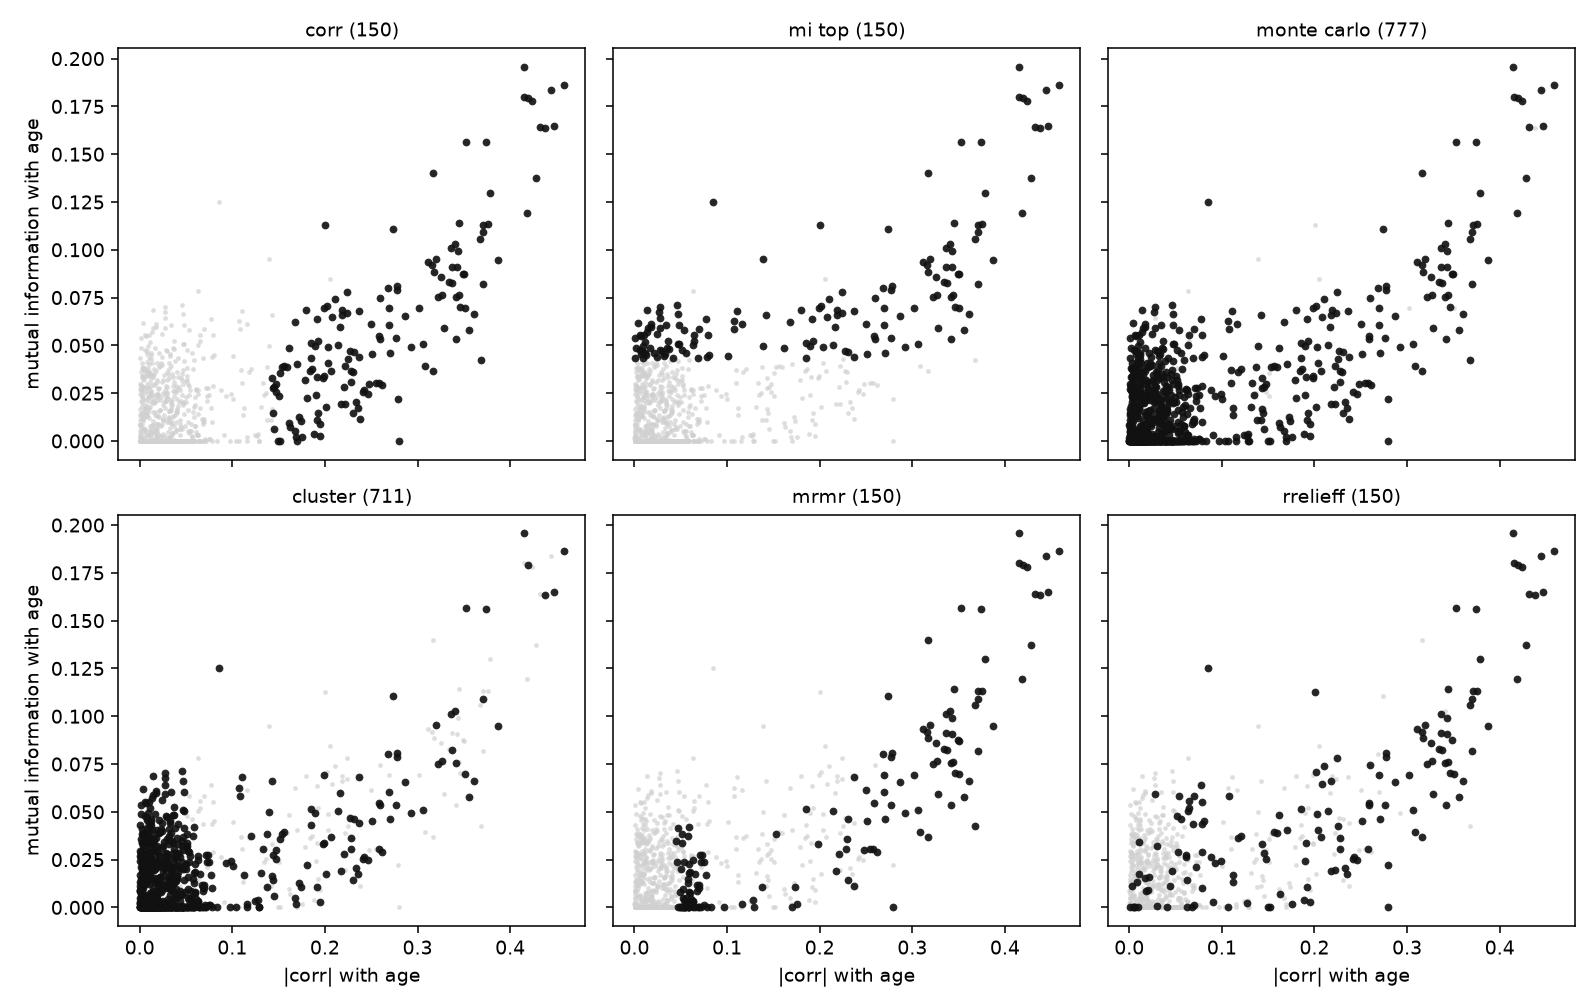

In [ ]:
from select_features import cluster as cluster_fs
from select_features import corr as corr_fs
from select_features import monte_carlo as monte_carlo_fs
from select_features import mrmr as mrmr_fs
from select_features import rrelieff as rrelieff_fs

X_cull = X_tr[kept]
sets = {
    "corr": corr_fs.select(X_cull, y_tr),
    "mi top": mi.loc[kept].nlargest(min(FS_K, len(kept))).index.tolist(),
    "monte carlo": monte_carlo_fs.select(X_cull, y_tr),
    "cluster": cluster_fs.select(X_cull, y_tr),
    "mrmr": mrmr_fs.select(X_cull, y_tr),
    "rrelieff": rrelieff_fs.select(X_cull, y_tr),
}

def bucket(col):
    if col in both:
        return "blue"
    if col in mi_only:
        return "green"
    if col in corr_only:
        return "orange"
    return "grey"

for name, cols in sets.items():
    counts = pd.Series([bucket(c) for c in cols]).value_counts()
    print(
        f"{name}: n={len(cols)}  "
        f"blue={counts.get('blue', 0)}  green={counts.get('green', 0)}  "
        f"orange={counts.get('orange', 0)}  grey={counts.get('grey', 0)}"
    )

fig, axes = plt.subplots(2, 3, figsize=(11.4, 7.2), sharex=True, sharey=True)
fig.patch.set_facecolor("white")
for ax, (name, cols) in zip(axes.ravel(), sets.items()):
    ax.set_facecolor("white")
    ax.scatter(abs_r, mi, s=6, c="#d0d0d0", alpha=0.7, linewidths=0)
    kept_cols = [c for c in cols if c in abs_r.index]
    ax.scatter(
        abs_r.loc[kept_cols],
        mi.loc[kept_cols],
        s=16,
        c="#111",
        alpha=0.9,
        linewidths=0,
    )
    ax.set_title(f"{name} ({len(cols)})", fontsize=10)
axes[1, 0].set_xlabel("|corr| with age")
axes[1, 1].set_xlabel("|corr| with age")
axes[1, 2].set_xlabel("|corr| with age")
axes[0, 0].set_ylabel("mutual information with age")
axes[1, 0].set_ylabel("mutual information with age")
fig.tight_layout()
fig.savefig(ROOT / "experiments/008/selector_panels.png", dpi=140)
show_fig(fig)